# Protocolo individual – Unidad IV · Ciencia de Datos II
**Clasificación del riesgo de bajo rendimiento académico**

## 1. Librerías y configuración
Importamos las herramientas: **pandas/numpy** para manejar datos, **matplotlib** para graficar y **scikit-learn** para los modelos y las métricas. Fijamos una semilla (`SEED`) para que el resultado sea siempre el mismo.

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SEED = 42
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
AZ, RJ, GR = "#1F4E79", "#C0392B", "#7F8C8D"

ModuleNotFoundError: No module named 'sklearn'

## 2. Carga de datos y variable objetivo
Los datos están en un archivo aparte: **`datos_simulados_riesgo.csv`** (400 estudiantes, una fila por estudiante).

In [ ]:
ARCHIVO = "datos_simulados_riesgo.csv"
if not os.path.exists(ARCHIVO):
    try:                                   # si estás en Google Colab, pide subir el archivo
        from google.colab import files
        print("Sube el archivo", ARCHIVO)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"No se encontró {ARCHIVO}. Ponlo en la misma carpeta que este cuaderno.")

df = pd.read_csv(ARCHIVO)
X, y = df.drop(columns="riesgo"), df["riesgo"]
N = len(df)
res = {"n": N, "riesgo_n": int(y.sum()), "riesgo_pct": round(100*y.mean(), 1)}
res["desc"] = df.describe().round(2).to_dict()
print(f"Estudiantes: {N} | en riesgo: {res['riesgo_n']} ({res['riesgo_pct']} %)")
df.describe().round(2)

Estudiantes: 400 | en riesgo: 130 (32.5 %)


,horas_estudio,asistencia_pct,actividades,calif_previas,promedio,asignaturas_aprobadas,riesgo
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,8.98,79.01,13.96,3.25,3.18,5.63,0.32
std,3.80,12.66,4.94,0.65,0.56,2.23,0.47
min,0.00,40.00,0.00,1.39,1.44,0.00,0.00
25%,6.30,70.05,11.00,2.79,2.80,4.00,0.00
50%,9.05,79.80,14.00,3.29,3.18,6.00,0.00
75%,11.40,87.72,17.00,3.69,3.56,7.00,1.00
max,20.70,100.00,30.00,4.94,4.66,10.00,1.00


## 3. División en entrenamiento y prueba, y modelos
Para saber si un modelo sirve con casos **nuevos**, no se evalúa con los mismos datos con los que aprendió. Por eso se separan:

- **75 % entrenamiento** (300 estudiantes): el modelo aprende aquí.
- **25 % prueba** (100 estudiantes): solo se usan para medir el resultado.

`stratify=y` mantiene la misma proporción de estudiantes en riesgo en ambos grupos.

Se entrenan dos modelos:

- **Random Forest** (modelo principal): muchos árboles de decisión que votan juntos. Se limita su profundidad para que no memorice.
- **Regresión logística** (referencia): un modelo más simple, con las variables estandarizadas.

`class_weight="balanced"` evita que el modelo ignore la clase menos frecuente (los estudiantes en riesgo).

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=5,
                            class_weight="balanced", random_state=SEED).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(Xtr, ytr)
print("Entrenamiento:", len(Xtr), "| Prueba:", len(Xte), "| En riesgo en prueba:", int(yte.sum()))

Entrenamiento: 300 | Prueba: 100 | En riesgo en prueba: 32


## 4. Métricas en el conjunto de prueba
Tomamos **"en riesgo" como clase positiva**:

| Métrica | Pregunta que responde |
|---|---|
| **Accuracy** | ¿Qué proporción del total se clasificó bien? |
| **Precisión** | De los marcados "en riesgo", ¿cuántos realmente lo estaban? |
| **Recall** | De los que realmente están en riesgo, ¿cuántos detectamos? |
| **F1** | Equilibrio entre precisión y recall |
| **AUC** | ¿Qué tan bien separa ambos grupos en todos los umbrales? |

Además se muestran los cuatro resultados de la matriz de confusión: verdaderos negativos (VN), falsos positivos (FP, falsas alarmas), falsos negativos (FN, casos en riesgo no detectados) y verdaderos positivos (VP).

Para este caso la métrica más importante es el **recall**, porque no detectar a un estudiante en riesgo es el error más costoso.

In [ ]:
def met(m):
    pr = m.predict(Xte); pb = m.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pr).ravel()
    return dict(acc=accuracy_score(yte, pr), prec=precision_score(yte, pr), rec=recall_score(yte, pr),
                f1=f1_score(yte, pr), auc=roc_auc_score(yte, pb), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

res["split"] = {"train": len(Xtr), "test": len(Xte), "test_riesgo": int(yte.sum())}
res["rf"], res["lr"] = met(rf), met(lr)
res["rf"]["acc_train"] = accuracy_score(ytr, rf.predict(Xtr))

tabla = pd.DataFrame({"Random Forest": res["rf"], "Regresión logística": res["lr"]}).T.round(3)
print("Referencia: decir siempre 'sin riesgo' acertaría", round(1 - yte.mean(), 2))
print("Accuracy del Random Forest en entrenamiento:", round(res["rf"]["acc_train"], 3), "(si es mucho mayor que en prueba, hay sobreajuste)")
tabla

Referencia: decir siempre 'sin riesgo' acertaría 0.68
Accuracy del Random Forest en entrenamiento: 0.887 (si es mucho mayor que en prueba, hay sobreajuste)


,acc,prec,rec,f1,auc,tn,fp,fn,tp,acc_train
Random Forest,0.78,0.639,0.719,0.676,0.785,55.0,13.0,9.0,23.0,0.887
Regresión logística,0.72,0.543,0.781,0.641,0.813,47.0,21.0,7.0,25.0,NaN


## 5. Validación cruzada
Una sola división de 100 estudiantes puede ser engañosa. La **validación cruzada estratificada de 5 pliegues** repite el entrenamiento y la prueba con cinco particiones distintas y reporta el promedio (± la variación). Si la variación es alta, el resultado depende mucho de la muestra.

In [ ]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for name, m in [("rf", rf), ("lr", lr)]:
    out = {}
    for sc in ["accuracy", "recall", "f1", "roc_auc"]:
        s = cross_val_score(m, X, y, cv=cv, scoring=sc)
        out[sc] = [round(s.mean(), 3), round(s.std(), 3)]
    res["cv_" + name] = out

pd.DataFrame({"Random Forest": {k: f"{v[0]} ± {v[1]}" for k, v in res["cv_rf"].items()},
              "Regresión logística": {k: f"{v[0]} ± {v[1]}" for k, v in res["cv_lr"].items()}}).T

,accuracy,recall,f1,roc_auc
Random Forest,0.762 ± 0.047,0.638 ± 0.13,0.631 ± 0.086,0.803 ± 0.069
Regresión logística,0.742 ± 0.035,0.731 ± 0.109,0.646 ± 0.054,0.809 ± 0.038


## 6. Visualizaciones
Cada gráfica responde una pregunta. Debajo de cada una se explica qué muestra.

### 6.1 Matriz de confusión
Cuenta los aciertos y errores del modelo. La diagonal son los aciertos; los otros dos cuadros son los errores. Los **falsos negativos** (abajo a la izquierda) son los estudiantes en riesgo que el modelo no detectó.

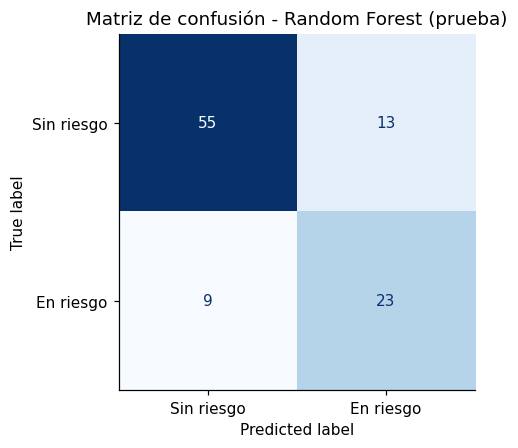

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_estimator(rf, Xte, yte, display_labels=["Sin riesgo", "En riesgo"],
                                      cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de confusión - Random Forest (prueba)"); ax.grid(False)
plt.tight_layout(); plt.savefig("figs/f1_confusion.png", dpi=170); plt.show()

### 6.2 Distribución de probabilidades predichas
Muestra qué tan seguro estaba el modelo en cada caso. Lo ideal es que los estudiantes sin riesgo (azul) queden a la izquierda y los que sí están en riesgo (rojo) a la derecha. Donde se mezclan, el modelo duda y es más probable que se equivoque: esos casos conviene revisarlos con una persona.

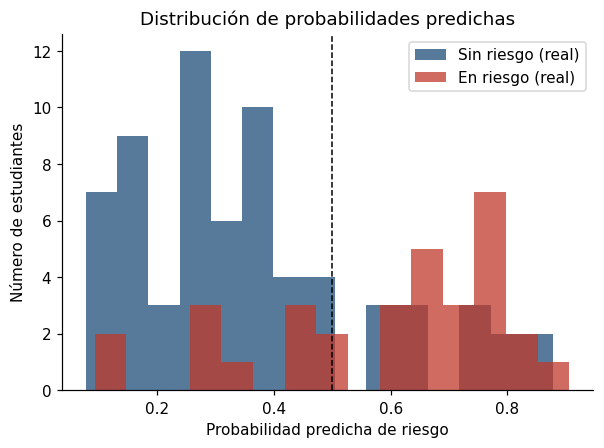

In [ ]:
pb = rf.predict_proba(Xte)[:, 1]
fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.hist(pb[yte == 0], bins=15, alpha=.75, color=AZ, label="Sin riesgo (real)")
ax.hist(pb[yte == 1], bins=15, alpha=.75, color=RJ, label="En riesgo (real)")
ax.axvline(0.5, color="k", ls="--", lw=1); ax.set_xlabel("Probabilidad predicha de riesgo")
ax.set_ylabel("Número de estudiantes"); ax.set_title("Distribución de probabilidades predichas"); ax.legend()
plt.tight_layout(); plt.savefig("figs/f2_probabilidades.png", dpi=170); plt.show()

### 6.3 Importancia de variables
Mide cuánto empeora el recall cuando se desordenan los valores de una variable: si baja mucho, el modelo depende de ella. **Ojo:** el promedio y las calificaciones previas están relacionados entre sí y comparten información; y como los datos son simulados, este orden refleja cómo se generaron, no un hallazgo sobre estudiantes reales.

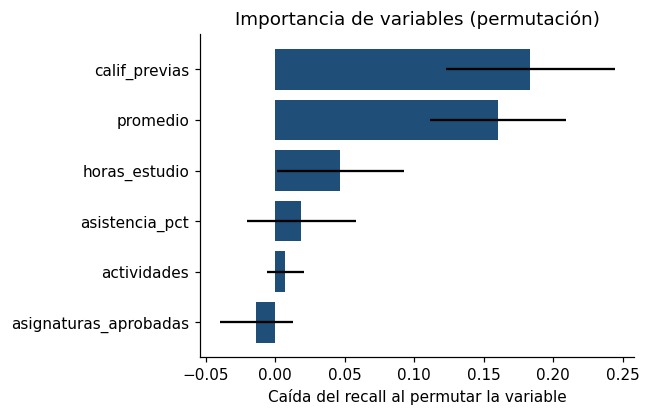

In [ ]:
pi = permutation_importance(rf, Xte, yte, n_repeats=30, random_state=SEED, scoring="recall")
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
res["perm_imp"] = imp.round(3).to_dict()
res["gini_imp"] = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).round(3).to_dict()

fig, ax = plt.subplots(figsize=(6, 3.9))
ax.barh(imp.index, imp.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color=AZ)
ax.set_xlabel("Caída del recall al permutar la variable"); ax.set_title("Importancia de variables (permutación)")
plt.tight_layout(); plt.savefig("figs/f3_importancia.png", dpi=170); plt.show()

### 6.4 Curva ROC
Compara ambos modelos en todos los umbrales posibles: cuanto más arriba y a la izquierda, mejor; la línea punteada es el azar. Si las curvas casi se superponen, el modelo más complejo no aporta una mejora clara.

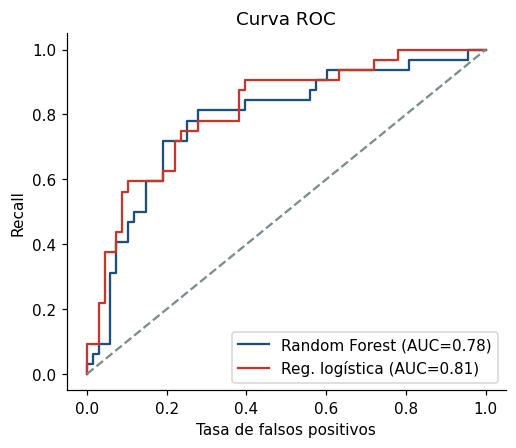

In [ ]:
fpr, tpr, _ = roc_curve(yte, pb); fpr2, tpr2, _ = roc_curve(yte, lr.predict_proba(Xte)[:, 1])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot(fpr, tpr, color=AZ, label=f"Random Forest (AUC={res['rf']['auc']:.2f})")
ax.plot(fpr2, tpr2, color=RJ, label=f"Reg. logística (AUC={res['lr']['auc']:.2f})")
ax.plot([0, 1], [0, 1], ls="--", color=GR); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Recall")
ax.set_title("Curva ROC"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figs/f4_roc.png", dpi=170); plt.show()

### 6.5 Variables según el nivel de riesgo
Compara el promedio, la asistencia y las horas de estudio entre estudiantes sin riesgo y en riesgo. Si las cajas se traslapan mucho, ninguna variable separa por sí sola a los grupos.

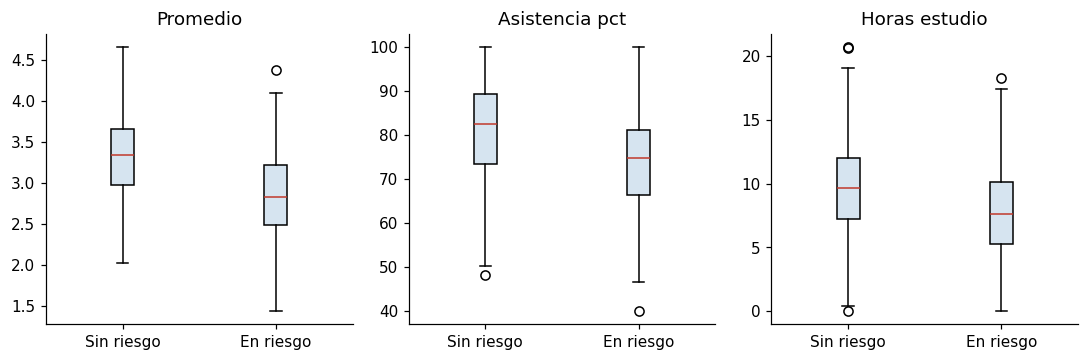

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
for a, c in zip(axs, ["promedio", "asistencia_pct", "horas_estudio"]):
    a.boxplot([df[df.riesgo == 0][c], df[df.riesgo == 1][c]], tick_labels=["Sin riesgo", "En riesgo"], patch_artist=True,
              boxprops=dict(facecolor="#D6E4F0"), medianprops=dict(color=RJ))
    a.set_title(c.replace("_", " ").capitalize())
plt.tight_layout(); plt.savefig("figs/f5_variables.png", dpi=170); plt.show()

## 7. Complemento no supervisado: perfiles con k-means
Hasta aquí usamos la etiqueta `riesgo`. Con **k-means** exploramos si los estudiantes forman grupos naturales **sin usar esa etiqueta**:

1. Se estandarizan las variables (k-means trabaja con distancias; sin esto, la asistencia de 0 a 100 dominaría a las demás).
2. Se calcula el **coeficiente de silueta**: valores bajos (menos de ~0,25) indican grupos poco separados.
3. Se elige k = 3 por interpretabilidad (es una decisión de criterio, no un resultado contundente).
4. Se describe cada grupo con promedios y su porcentaje de estudiantes en riesgo.

Los grupos son una **exploración**, no categorías oficiales de los estudiantes.

In [ ]:
sc = StandardScaler().fit(X); Xs = sc.transform(X)
sil = {k: round(silhouette_score(Xs, KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)), 3) for k in range(2, 7)}
res["silhouette"] = sil
print("Silueta por k:", sil)

km = KMeans(3, n_init=10, random_state=SEED).fit(Xs); df["grupo"] = km.labels_
prof = df.groupby("grupo").agg(n=("riesgo", "size"), pct_riesgo=("riesgo", lambda s: round(100*s.mean(), 1)),
    horas=("horas_estudio", "mean"), asist=("asistencia_pct", "mean"), activ=("actividades", "mean"),
    notas=("calif_previas", "mean"), prom=("promedio", "mean"), aprob=("asignaturas_aprobadas", "mean")).round(2)
order = prof.sort_values("pct_riesgo", ascending=False).index.tolist()
prof = prof.loc[order]; res["perfiles"] = prof.reset_index().to_dict("records")
prof

Silueta por k: {2: 0.2, 3: 0.157, 4: 0.138, 5: 0.148, 6: 0.143}


,n,pct_riesgo,horas,asist,activ,notas,prom,aprob
grupo,,,,,,,,
1,143,62.2,7.30,73.13,13.94,2.63,2.64,4.94
2,137,21.2,7.72,85.23,11.07,3.65,3.56,5.99
0,120,10.0,12.43,78.92,17.27,3.53,3.37,6.05


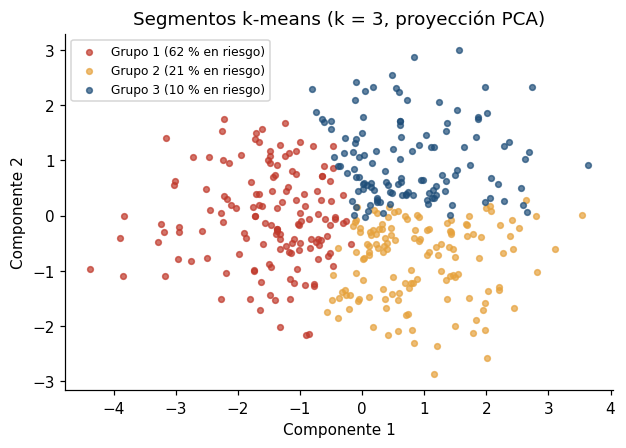

In [ ]:
pc = PCA(2, random_state=SEED).fit_transform(Xs)
fig, ax = plt.subplots(figsize=(5.8, 4.2))
cols = {order[0]: RJ, order[1]: "#E6A23C", order[2]: AZ}
for g in order:
    ax.scatter(pc[km.labels_ == g, 0], pc[km.labels_ == g, 1], s=14, alpha=.7, color=cols[g],
               label=f"Grupo {order.index(g)+1} ({prof.loc[g,'pct_riesgo']:.0f} % en riesgo)")
ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2"); ax.set_title("Segmentos k-means (k = 3, proyección PCA)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/f6_clusters.png", dpi=170); plt.show()

## 8. Guardar resultados
Se guardan todas las métricas en un archivo `resultados.json`, para usarlas en el informe y la presentación.

In [ ]:
json.dump(res, open("resultados.json", "w"), ensure_ascii=False, indent=1, default=float)
print("Listo: resultados.json y figuras en la carpeta figs/")

Listo: resultados.json y figuras en la carpeta figs/


## Interpretacion de los resultados
- **Desempeño:** el modelo detecta el riesgo mejor que el azar, pero con un desempeño **moderado**: su accuracy solo supera en unos 10 puntos a la referencia de decir siempre "sin riesgo".
- **Error más delicado:** los falsos negativos (estudiantes en riesgo no detectados). Por eso se prioriza el **recall**, leyéndolo junto con la precisión para controlar las falsas alarmas.
- **Comparación de modelos:** la regresión logística detecta más casos en riesgo pero genera más falsas alarmas; el Random Forest hace lo contrario. Con la variación de la validación cruzada, no hay un ganador claro.
- **Límites:** datos simulados, muestra pequeña, pocas variables y sin análisis por subgrupos.
- **Uso responsable:** una predicción es una probabilidad, no un veredicto. Sirve para orientar apoyo (tutorías, seguimiento), siempre con revisión humana, y no para sancionar o excluir.